<div dir="rtl" style="text-align:right"><h1>להעמיק: מרשתות נוירונים למודלי שפה</h1>
<p>יישומי בינה מלאכותית AI | מחברת העשרה לשיעור 3. <b>רשות, ואין חובת הגשת מחברת.</b></p>
<ol>
<li><b>נוירון אחד</b> – סכום משוקלל וסף, ביד.</li>
<li><b>רשת קטנה לומדת</b> – אימון על נתוני מאפייה בדויים: השגיאה יורדת, וקו ההחלטה זז.</li>
<li><b>ייצוגים</b> – מספרים אמיתיים ממודל ייצוגים פתוח: דמיון בין מילים בעברית ובאנגלית, ומפה בשני ממדים.</li>
</ol>
<p>מריצים תא אחרי תא בלחיצה על ▶. מעבד רגיל (<code>CPU</code>) מספיק; אין צורך ב-<code>GPU</code>, במפתח <code>API</code> או במנוי. סעיף 3 מוריד מודל פתוח של כ-470MB. אזהרה על <code>HF_TOKEN</code> – אפשר להתעלם.</p></div>

In [1]:
# Setup. Everything below is preinstalled on Google Colab.
import warnings

import matplotlib.pyplot as plt
import numpy as np
import sklearn
import torch
import transformers
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)
print("scikit-learn", sklearn.__version__, "| transformers", transformers.__version__, "| torch", torch.__version__)


def rtl(text):
    # matplotlib draws left to right; reversing a Hebrew word displays it correctly.
    return text[::-1] if any("\u0590" <= ch <= "\u05ff" for ch in text) else text

scikit-learn 1.9.1 | transformers 5.22.1 | torch 2.15.0+cpu


<div dir="rtl" style="text-align:right"><h2>1 | נוירון אחד</h2>
<p><b>נוירון</b> (בתוכנה) הוא חישוב פשוט: כל קלט מוכפל ב<b>משקל</b>, מחברים הכול, מוסיפים <b>הטיה</b> (<code>bias</code>), ובודקים אם הסכום עבר סף. כאן: האם המאפייה צריכה לאפות עוד מגש עוגיות למחר?</p>
<ul>
<li>הזמנות מראש למחר – משקל חיובי: כל הזמנה דוחפת לאפות.</li>
<li>מגשים שנשארו מהיום – משקל שלילי: כל מגש שנשאר מושך לא לאפות.</li>
</ul>
<p>את המשקלים כאן בחרנו ביד. ברשת אמיתית <b>האימון</b> קובע אותם – זה סעיף 2.</p></div>

In [2]:
def neuron(inputs, weights, bias):
    total = sum(x * w for x, w in zip(inputs, weights)) + bias
    return total, (1 if total >= 0 else 0)


weights = [0.5, -1.0]  # orders, leftover trays (chosen by hand)
bias = -2.0
for orders, leftover in [(6, 3), (10, 1), (4, 0)]:
    total, decision = neuron([orders, leftover], weights, bias)
    print(f"orders={orders:2}  leftover={leftover}  ->  sum={total:5.1f}  ->  {'bake another tray' if decision else 'no extra tray'}")

orders= 6  leftover=3  ->  sum= -2.0  ->  no extra tray
orders=10  leftover=1  ->  sum=  2.0  ->  bake another tray
orders= 4  leftover=0  ->  sum=  0.0  ->  bake another tray


<div dir="rtl" style="text-align:right"><blockquote>נסו: שנו את <code>weights</code> או את <code>bias</code> והריצו שוב. איזה שינוי הופך את ההחלטה במקרה הראשון?</blockquote>
<h2>2 | רשת קטנה לומדת מדוגמאות</h2>
<p><b>רשת נוירונים</b> היא שכבות של נוירונים כאלה: הפלט של שכבה אחת הוא הקלט של הבאה. <b>אימון</b> (כמו בשיעור 2) פירושו לשנות את המשקלים צעד אחרי צעד, כך שהשגיאה על דוגמאות האימון קטנה. הנתונים כאן <b>בדויים</b>: כלל פשוט עם מעט רעש קובע אם היה צריך עוד מגש.</p>
<p>נשתמש ב-<code>MLPClassifier</code> של <code>scikit-learn</code>: רשת עם שכבה נסתרת אחת של 8 נוירונים.</p></div>

In [3]:
rng = np.random.default_rng(3)
orders = rng.integers(0, 21, 160).astype(float)
leftover = rng.integers(0, 11, 160).astype(float)
needed = (orders - 1.5 * leftover + rng.normal(0, 1.5, 160) > 5).astype(int)  # made-up rule + noise
X = np.column_stack([orders / 20, leftover / 10])  # scaled to 0..1
X_train, y_train, X_test, y_test = X[:120], needed[:120], X[120:], needed[120:]

net = MLPClassifier(hidden_layer_sizes=(8,), learning_rate_init=0.005, max_iter=1, warm_start=True, random_state=0)
losses, snapshots, train_acc = [], {}, {}
for epoch in range(1, 301):
    net.fit(X_train, y_train)  # one training step (one pass over the 120 examples)
    losses.append(net.loss_)
    if epoch in (1, 300):
        snapshots[epoch] = (net.coefs_[0].copy(), net.intercepts_[0].copy(), net.coefs_[1].copy(), net.intercepts_[1].copy())
        train_acc[epoch] = net.score(X_train, y_train)
print(f"loss after 1 step: {losses[0]:.3f}   after 300 steps: {losses[-1]:.3f}")
print(f"accuracy on the training examples: {train_acc[1]:.0%} after 1 step, {train_acc[300]:.0%} after 300")
print(f"accuracy on 40 examples the network did not train on: {net.score(X_test, y_test):.0%}")

loss after 1 step: 0.647   after 300 steps: 0.151
accuracy on the training examples: 66% after 1 step, 92% after 300
accuracy on 40 examples the network did not train on: 90%


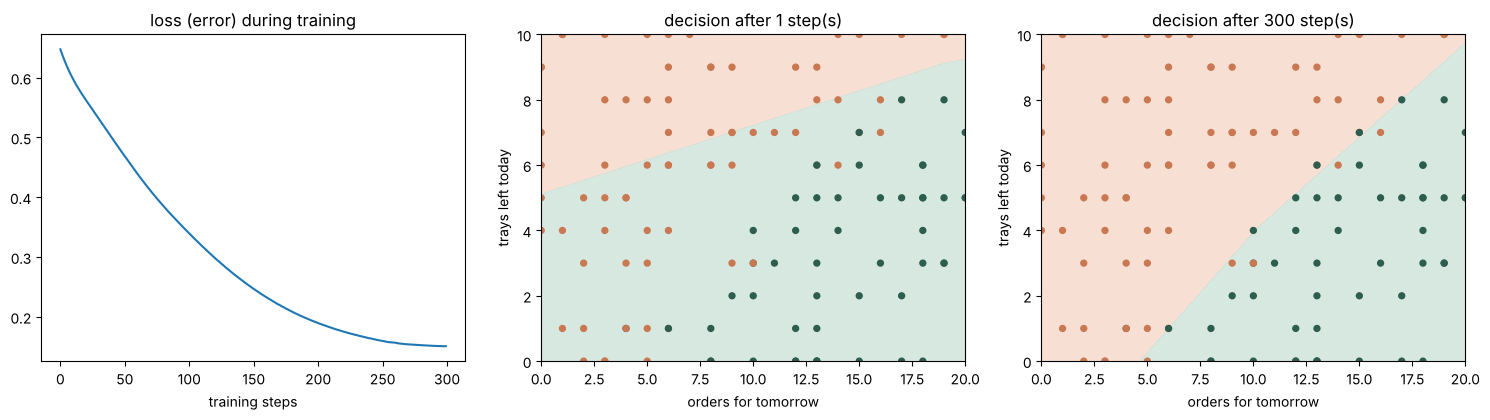

In [4]:
def predict_with(snapshot, points):
    w1, b1, w2, b2 = snapshot
    hidden = np.maximum(0, points @ w1 + b1)  # ReLU
    return (1 / (1 + np.exp(-(hidden @ w2 + b2)))).ravel()


grid_x, grid_y = np.meshgrid(np.linspace(0, 1, 120), np.linspace(0, 1, 120))
grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(losses)
axes[0].set_title("loss (error) during training")
axes[0].set_xlabel("training steps")
for ax, epoch in zip(axes[1:], (1, 300)):
    p = predict_with(snapshots[epoch], grid).reshape(grid_x.shape)
    ax.contourf(grid_x * 20, grid_y * 10, p, levels=[0, 0.5, 1], colors=["#f5d9c8", "#cee3da"], alpha=0.8)
    ax.scatter(X_train[:, 0] * 20, X_train[:, 1] * 10, c=np.where(y_train, "#2d5d4f", "#c97852"), s=18)
    ax.set_title(f"decision after {epoch} step(s)")
    ax.set_xlabel("orders for tomorrow")
    ax.set_ylabel("trays left today")
plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align:right"><p>משמאל: השגיאה יורדת לאורך האימון. באמצע ומימין: האזור הירוק הוא «לאפות עוד מגש». אחרי צעד אחד הרשת עוד כמעט לא מבחינה בין המקרים; אחרי 300 צעדים הקו מפריד את רוב הנקודות (לא את כולן – יש רעש בנתונים). אף אחד לא כתב את הכלל ביד – האימון כיוונן את המשקלים.</p>
<p><b>הגבלה:</b> אלה נתונים בדויים ורשת זעירה. מודל שפה עובר את אותו רעיון בסיסי – לשנות משקלים כדי להקטין שגיאה – אבל על כמויות עצומות של טקסט ועם מיליארדי משקלים.</p>
<h2>3 | ייצוגים (embeddings)</h2>
<p><b>ייצוג</b> הוא רשימת מספרים שמודל נותן לטקסט. למילים עם משמעות דומה יש ייצוגים קרובים. נשתמש במודל הייצוגים הפתוח <code>sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2</code> (מודל קטן, רב-לשוני; לכל טקסט 384 מספרים). זה לא המודל של הצ׳טבוט שלכם.</p>
<p><b>דמיון קוסינוס</b> משווה שתי רשימות מספרים: קרוב ל-1 – דומות מאוד; קרוב ל-0 – לא קשורות.</p></div>

In [5]:
from transformers import AutoModel, AutoTokenizer

EMB_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
emb_tok = AutoTokenizer.from_pretrained(EMB_MODEL)
emb_model = AutoModel.from_pretrained(EMB_MODEL)
emb_model.eval()


def embed(texts):
    batch = emb_tok(texts, padding=True, return_tensors="pt")
    with torch.no_grad():
        out = emb_model(**batch).last_hidden_state
    mask = batch["attention_mask"].unsqueeze(-1).float()
    return ((out * mask).sum(1) / mask.sum(1)).numpy()  # mean pooling


def cosine(a, b):
    va, vb = embed([a, b])
    return float(va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb)))


print("vector length:", embed(["לחם"]).shape[1])
for a, b in [("לחם", "bread"), ("לחם", "עוגה"), ("לחם", "קפה"), ("לחם", "שמח"), ("מחר", "tomorrow"), ("שמח", "עצוב")]:
    print(f"{a:>6} ~ {b:<8}  cosine = {cosine(a, b):.2f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2779.06it/s]

vector length: 384
   לחם ~ bread     cosine = 0.99
   לחם ~ עוגה      cosine = 0.51
   לחם ~ קפה       cosine = 0.37
   לחם ~ שמח       cosine = 0.31
   מחר ~ tomorrow  cosine = 0.98
   שמח ~ עצוב      cosine = 0.42


<div dir="rtl" style="text-align:right"><p>שימו לב: «שמח» ו«עצוב» הפוכים במשמעות, ובכל זאת קרובים למדי – שתיהן מילים של רגש שמופיעות בהקשרים דומים. ייצוגים משקפים <b>הקשרים שבהם מילים מופיעות</b>, לא הגדרה של משמעות.</p>
<h3>3א | מפה בשני ממדים</h3>
<p>384 מספרים אי אפשר לצייר. <code>PCA</code> דוחס אותם לשניים, ולכן <b>המרחקים במפה משוערים</b>: מילים יכולות להיראות קרובות או רחוקות יותר מכפי שהן במלוא הממדים.</p></div>

the 2D map keeps 49% of the variance


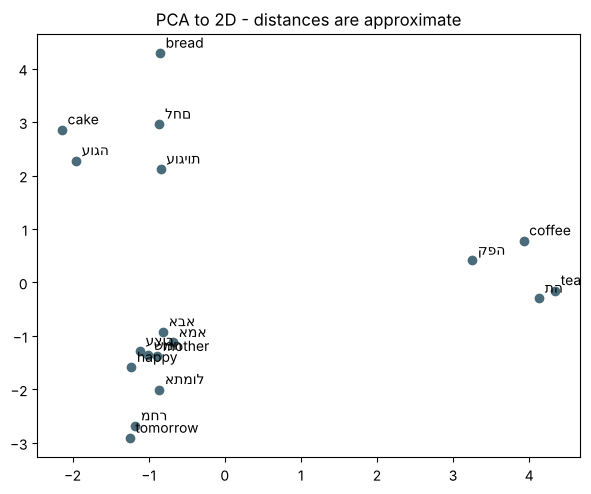

In [6]:
words = ["לחם", "עוגה", "עוגיות", "bread", "cake", "קפה", "תה", "coffee", "tea",
         "מחר", "אתמול", "tomorrow", "שמח", "עצוב", "happy", "אמא", "אבא", "mother"]
vectors = embed(words)
centered = vectors - vectors.mean(0)
_, singular, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T
print(f"the 2D map keeps {(singular[:2] ** 2).sum() / (singular ** 2).sum():.0%} of the variance")

plt.figure(figsize=(7, 5.5))
plt.scatter(xy[:, 0], xy[:, 1], color="#4a6c7a")
for (x, y), w in zip(xy, words):
    plt.annotate(rtl(w), (x, y), textcoords="offset points", xytext=(4, 4))
plt.title("PCA to 2D - distances are approximate")
plt.show()

<div dir="rtl" style="text-align:right"><h2>4 | מה ראינו</h2>
<ul>
<li><b>נוירון:</b> סכום משוקלל, הטיה וסף. המשקלים קובעים מה חשוב.</li>
<li><b>אימון:</b> משנים משקלים צעד אחרי צעד כדי להקטין שגיאה. אחרי האימון המשקלים קבועים, ומשתמשים ברשת לחיזוי.</li>
<li><b>ייצוגים:</b> טקסט הופך לרשימת מספרים; דמיון בין רשימות משקף הקשרים שנלמדו – גם בין עברית לאנגלית, וגם עם מוזרויות.</li>
</ul>
<p>מודל שפה בונה על כל אלה: טוקנים הופכים לייצוגים, שכבות של קשב ורשתות קטנות מעבדות אותם, ובסוף מתקבלות הסתברויות לטוקן הבא. חזרו לאתר להמשך.</p></div>